In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.integrate import solve_ivp, ode
from scipy.optimize import fsolve, differential_evolution
from mpl_toolkits.mplot3d import Axes3D
%matplotlib inline

# Periodic Halo Orbit Finding and Analysis

This work doesn't include quasi-periodic halo orbits because of the mathematical and computational requirements. It was attempted but ultimately ended up being too challenging to implement completely. Still, analysis of periodic orbits is very similar in both the matrices used and overall behavior.

### Equations of motion

In [3]:
def solve_l2point(mu):
    # quintic
    alpha = (mu/(3 * (1 - mu)))**(1/3)
    u0 = alpha * (1 + alpha/3 - alpha**2/9)
    def l2_eqn(u):
        return u**2 * (u**3 + 3*u**2 + 3*u) - mu*(u**4 + 2*u**3 + u**2 + 2*u + 1)
    u = fsolve(l2_eqn, x0=u0)
    return u[0]

def get_jacobian(state, mu):
    x, y, z, xdot, ydot, zdot = state[:]
    r1 = np.sqrt((x + mu)**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1 + mu)**2 + y**2 + z**2)

    Uxx = 1 - (1-mu)/r1**3 - mu/r2**3 +3*((x+mu)**2 * (1-mu)/r1**5 + (x + mu - 1)**2 * mu/r2**5)
    Uyy = 1 - (1-mu)/r1**3 - mu/r2**3 +3*y**2*((1-mu)/r1**5 + mu/r2**5)
    Uzz = -(1-mu)/r1**3 - mu/r2**3 + 3*z**2*((1-mu)/r1**5 + mu/r2**5)
    Uxy = Uyx = 3*y*((x+mu)*(1-mu)/r1**5 + (x + mu - 1)*mu/r2**5)
    Uxz = Uzx = 3*z*((x+mu)*(1-mu)/r1**5 + (x + mu - 1)*mu/r2**5)
    Uyz = Uzy = 3*y*z*((1-mu)/r1**5 + mu/r2**5)
    U_lap = np.array([[Uxx, Uxy, Uxz], [Uyx, Uyy, Uyz], [Uzx, Uzy, Uzz]])

    coriolis = np.array([[0,1,0],[-1,0,0],[0,0,0]])
    A = np.zeros((6, 6))
    A[:3,:3] = np.zeros((3,3))
    A[0:3,3:6] = np.eye(3)
    A[3:6,0:3] = U_lap
    A[3:6,3:6] = 2 * coriolis
    return A

def f(t, state, mu):
    x, y, z, xdot, ydot, zdot = state[:]
    r1 = np.sqrt((x + mu)**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1 + mu)**2 + y**2 + z**2)

    xddot = 2*ydot + x - ((1-mu)/r1**3)*(x + mu) + (mu/r2**3)*(1 - mu - x)
    yddot = -2*xdot + y - ((1-mu)/r1**3)*y - (mu/r2**3)*y
    zddot = - ((1-mu)/r1**3)*z - (mu/r2**3)*z

    return np.array([xdot, ydot, zdot, xddot, yddot, zddot])

def derivs(t, full_state, mu):
    state = full_state[:6]
    Phi = full_state[6:].reshape(6, 6)
    A = get_jacobian(state, mu)
    Phidot = A @ Phi

    return np.concatenate((f(t, state, mu), Phidot.flatten()))

def deriv(t, X, mu):
    x, y, z, xdot, ydot, zdot = X
    r1 = np.sqrt((x      + mu)**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1. + mu)**2 + y**2 + z**2)

    term_1 = x + 2. * ydot
    term_2 = -(1.-mu) * (x + mu) / r1**3
    term_3 =     -mu  * (x - 1. + mu) / r2**3
    xddot  = term_1 + term_2 + term_3

    term_1 = -2. * xdot
    term_2 = 1. - (1.-mu)/r1**3 - mu/r2**3 
    yddot  = term_1 + y * term_2

    term_1 = (1. - mu)/r1**3 + mu/r2**3
    zddot  = -z * term_1

    return np.array([xdot, ydot, zdot, xddot, yddot, zddot])

def jacobi_constant(state, mu):
    x, y, z, vx, vy, vz = state
    r1 = np.sqrt((x+mu)**2   + y**2 + z**2)
    r2 = np.sqrt((x-1+mu)**2 + y**2 + z**2)
    v2 = vx**2 + vy**2 + vz**2
    U  = (x**2 + y**2)/2 + (1-mu)/r1 + mu/r2
    return 2*U - v2

In [4]:
M_E = 5.972e24
M_S = 1.989e30
r12 = AU = 149_597_870.700
mu = M_E / (M_E + M_S)

u2 = solve_l2point(mu)

## Breakwell & Brown (1979) Differential Correction Algorithm

In [5]:
def iteration(X0,T):
    Phi0 = np.eye(6)
    state0 = np.concatenate((X0, Phi0.flatten()), axis=0)

    def y_zero(t, s, mu):
        return s[1]
    y_zero.terminal = False
    y_zero.direction = -1 

    n_half=1200
    sol = solve_ivp(
        derivs,
        args=(mu,),
        t_span = (0.0, T),
        y0 = state0,
        method = 'DOP853',
        events = y_zero,
        t_eval= T * np.linspace(0.0, 1.0, 2*n_half+1),
        rtol = 1e-11,
        atol = 1e-12,
        dense_output = False)

    if not sol.t_events[0].size:
        print('No Y crossing')
        return None

    s_half = sol.y_events[0][0]
    X_half = s_half[:6]
    Phi = s_half[6:].reshape((6,6))
    f_half = f(0,X_half, mu)

    M = np.array([[Phi[3,0] - (f_half[3]/f_half[1])*Phi[1,0],
                    Phi[3,4] - (f_half[3]/f_half[1])*Phi[1,4]],
                    [Phi[5,0] - (f_half[5]/f_half[1])*Phi[1,0],
                    Phi[5,4] - (f_half[5]/f_half[1])*Phi[1,4]]])
    delta_free = - np.linalg.inv(M) @ np.array([X_half[3], X_half[5]]).T

    return delta_free, sol

In [6]:
def BB1979(z0, mu, x0, ydot0, r12, T):

    X0 = np.array([x0, 0, z0, 0, ydot0, 0])
 
    u2 = solve_l2point(mu)
    xL2 = u2 + 1 - mu
    #fig, axs = plt.subplots(3,2,figsize=(10,8),dpi=100,projection='3d')
    fig = plt.figure(figsize=(8,10),dpi=200,constrained_layout=True)
    axs = []
    for k in range(4):
        delta_free, sol = iteration(X0, T)
        X0 = X0 + np.array([delta_free[0], 0, 0, 0, delta_free[1], 0])
        r, c = k % 6, k // 6
        ax = fig.add_subplot(3, 2, k+1, projection='3d')#axs[r, c]

        ax.plot([xL2*r12], [0], [0], 'ok', markersize=8)
        x, y, z = sol.y[:3]
        im = ax.scatter(x * r12, y * r12, z * r12, c=sol.t/T)

        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.view_init(elev=30, azim=310, roll=0)
 
        ax.set_xlim(1.007*r12, 1.028*r12)
        ax.set_ylim(-0.025*r12, 0.005*r12)
        ax.set_zlim(-0.0015*r12,0.0013*r12)

        axs.append(ax)
    
    fig.colorbar(im, ax=axs, fraction=0.01)
    plt.show()

    return X0


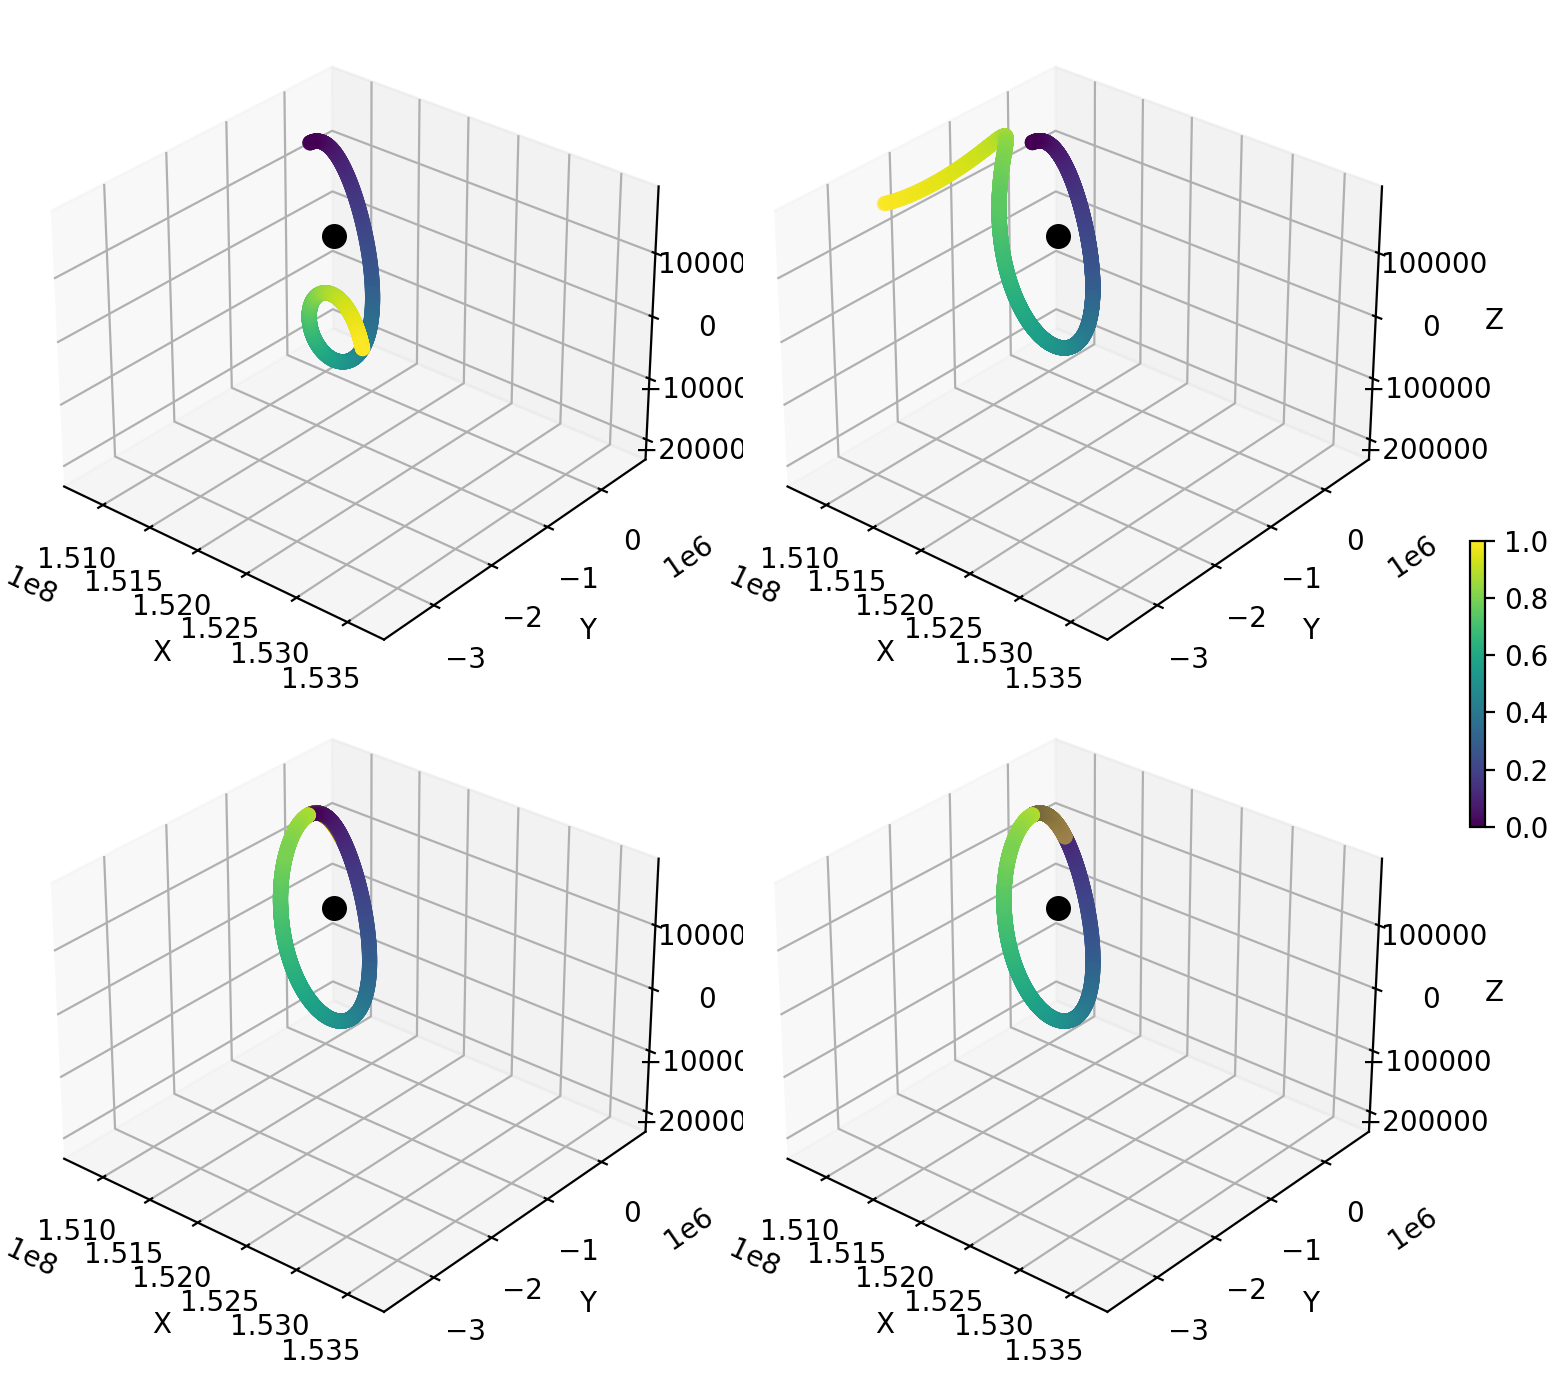

In [7]:
# free parameter is z0
z0 = 9.09018724526800e-04

x0 = 1.00833444281154e+00
ydot0 = 9.93564036550147e-03
X0 = BB1979(z0, mu, x0, ydot0, r12, T=3.5)

## More Orbits in the Family

In [ ]:
z0_og = 0.00118172
x0_og = 1.00822508
ydot0_og = 0.01027304

z0_range = z0_og * np.linspace(1.0, 4.0, 80)
# z0_range = [z0_og, z0_og*1.25, z0_og*1.50,z0_og*1.75,z0_og*2.0,z0_og*2.25,z0_og*2.5]
T = 3.5
X0_range = []
sol_range = []
x0_prev, ydot0_prev = x0_og, ydot0_og
for i, z0 in enumerate(z0_range):
    X0_ = np.array([x0_prev, 0, z0, 0, ydot0_prev, 0]) 
    for k in range(6):
        delta_free, sol = iteration(X0_,T)
        X0_ = X0_ + np.array([delta_free[0], 0, 0, 0, delta_free[1], 0])
    x0_prev, ydot0_prev = X0_[0], X0_[4]
    X0_range.append(X0_)
    sol_range.append(sol)

In [ ]:
X0_range = np.array(X0_range)
np.save('X0s_saved.npy', X0_range)

Optional plot showing the orbits. Almost the same as is shown in the next section.

In [ ]:
# %matplotlib qt
fig = plt.figure(figsize=(6,6),dpi=200,constrained_layout=True)
ax = fig.add_subplot(1,1,1,projection='3d')
for j, sol in enumerate(sol_range):
    x, y, z = sol.y[:3]
    ax.plot(x*r12, y*r12, z*r12, c='tab:blue',label=str(j))
u2 = solve_l2point(mu)
xL2 = u2 + 1 - mu
ax.set_xlim((xL2 - 0.02)*r12, (xL2 + 0.02)*r12)
ax.set_ylim(-0.02*r12, 0.02*r12)
ax.set_zlim(-0.02*r12,0.02*r12)
ax.set_xlabel('X [km]')
ax.set_ylabel('Y [km]')
ax.set_zlabel('Z [km]')
ax.view_init(elev=30, azim=310, roll=0)
ax.plot([xL2*r12], [0], [0], 'ok', markersize=8)
ax.text(xL2*r12, 0, -0.3*z[0]*r12, "L2", fontsize=8, horizontalalignment='center')
# fig.legend()
fig.suptitle('Periodic Halo Orbit Family')
plt.show()

## Stability of Periodic Halo Orbits

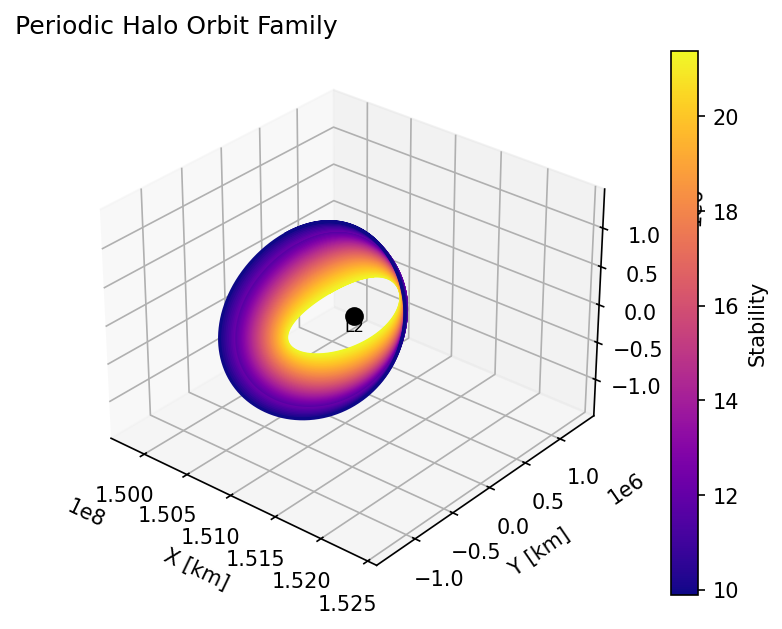

In [ ]:
fig = plt.figure(figsize=(8,4),dpi=150,constrained_layout=True)
ax = fig.add_subplot(1,1,1,projection='3d')
stability_indices = []
sols = []

for j, X0 in enumerate(X0_range):
    Phi0 = np.eye(6)
    state0 = np.concatenate((X0, Phi0.flatten()), axis=0)

    def y_zero(t, s, mu):
        return s[1]
    y_zero.terminal = False
    #y_zero.direction = -1 

    n_half=1200
    sol = solve_ivp(
        derivs,
        args=(mu,),
        t_span = (0.0, T),
        y0 = state0,
        method = 'DOP853',
        events = y_zero,
        t_eval= T * np.linspace(0.0, 1.0, 2*n_half+1),
        rtol = 1e-11,
        atol = 1e-12,
        dense_output = False)

    if not sol.t_events[0].size:
        print('No Y crossing')

    s_T = sol.y_events[0][-2]
    X_T = s_T[:6]
    monodromy = s_T[6:].reshape((6,6))
    eigendecomp = np.linalg.eig(monodromy)
    eigenvalues = list(eigendecomp.eigenvalues)

    lam_max = np.abs(eigenvalues)[2]
    stability_index = 0.5*(np.abs(eigenvalues)[0] + np.abs(eigenvalues)[1])#(lam_max + 1/lam_max)
 
    sols.append(sol)
    stability_indices.append(stability_index)

cmap = cm.plasma
norm = plt.Normalize(vmin=np.min(stability_indices), vmax=np.max(stability_indices))
for sol, ind in zip(sols, stability_indices):
    x, y, z = sol.y[:3]
    ax.plot(x*r12, y*r12, z*r12, c=cmap(norm(ind)), label=str(j))
    u2 = solve_l2point(mu)
    xL2 = u2 + 1 - mu
    ax.set_xlim((xL2 - 0.01)*r12, (xL2 + 0.01)*r12)
    ax.set_ylim(-0.01*r12, 0.01*r12)
    ax.set_zlim(-0.01*r12,0.01*r12)
    ax.set_xlabel('X [km]')
    ax.set_ylabel('Y [km]')
    ax.set_zlabel('Z [km]')
    ax.view_init(elev=30, azim=310, roll=0)
ax.plot([xL2*r12], [0], [0], 'ok', markersize=8)
ax.text(xL2*r12, 0, -0.3*z[0]*r12, "L2", fontsize=8, horizontalalignment='center')
mappable = cm.ScalarMappable(norm=norm,cmap=cmap)
cbar = plt.colorbar(mappable, ax=plt.gca(),label='Stability')
fig.suptitle('Periodic Halo Orbit Family')
plt.show()

In [ ]:
X0s = np.load('X0s_saved.npy')
X0 = X0s[-1]
# improve using differential evolution

### Differential Evolution

Alternative method for finding initial conditions. Works well but is less elegant than differential correction. Similar to diffrential correction, it needs a somewhat reasonable starting point.

In [ ]:
def objective(params, T0, mu):
    x0, z0, ydot0 = params
    s0 = [x0, 0.0, z0, 0.0, ydot0, 0.0]

    def y_cross(t, s, T):  # event is y=0 crossing
        return s[1]
    y_cross.terminal  = False
    y_cross.direction = -1
    n_half = 1200
    sol = solve_ivp(deriv, 
        t_span = (0.0, T0),
        args=(mu,),
        y0 = s0,
        method = 'DOP853',
        t_eval= T0 * np.linspace(0.0, 1.0, 2*n_half+1), 
        events=y_cross, rtol=1e-12, atol=1e-13)

    if not sol.t_events[0].size:
        return 1e6
    s_half = sol.y_events[0][-1]
    vx_err = s_half[3]
    vz_err = s_half[5]

    return vx_err**2 + vz_err**2

In [ ]:
FRAC = 0.005
bounds = [
    (X0[0] * (1 - FRAC), X0[0] * (1 + FRAC)),
    (X0[2] * (1 - FRAC), X0[2] * (1 + FRAC)),
    (X0[4] * (1 - FRAC), X0[4] * (1 + FRAC)),
]
T = 3.5
result = differential_evolution(
    objective, bounds,
    args=(T,mu),
    strategy='best1bin',
    maxiter=60,
    popsize=20,
    tol=1e-16,
    mutation=(0.4, 0.9),
    recombination=0.95,
    seed=42,
    polish=True,
    disp=False
)
x0, z0, ydot0 = result.x
print(f'x0 = {x0:.12f}')
print(f'z0 = {z0:.12f}')
print(f'ydot0 = {ydot0:.12f}')
print(f'residual = {result.fun:.3e}')
print(f'{result.message}')

differential_evolution step 1: f(x)= 4.177347276898326e-07
differential_evolution step 2: f(x)= 3.842075404437844e-07
differential_evolution step 3: f(x)= 3.842075404437844e-07
differential_evolution step 4: f(x)= 6.687060675059818e-08
differential_evolution step 5: f(x)= 6.687060675059818e-08
differential_evolution step 6: f(x)= 6.687060675059818e-08
differential_evolution step 7: f(x)= 6.687060675059818e-08
differential_evolution step 8: f(x)= 3.11238786698504e-08
differential_evolution step 9: f(x)= 3.11238786698504e-08
differential_evolution step 10: f(x)= 3.11238786698504e-08
differential_evolution step 11: f(x)= 2.298215041631819e-08
differential_evolution step 12: f(x)= 2.298215041631819e-08
differential_evolution step 13: f(x)= 2.3169932285699755e-09
differential_evolution step 14: f(x)= 6.223300420957221e-10
differential_evolution step 15: f(x)= 5.800501951526146e-10
differential_evolution step 16: f(x)= 1.2109036580524413e-10
differential_evolution step 17: f(x)= 1.2109036580

### Stationkeeping

#### Differential Correction Approach

In [ ]:
def iteration(X_low,T_half,X_nom,mu):
    Phi0 = np.eye(6)
    state0 = np.concatenate((X_low, Phi0.flatten()), axis=0)

    def y_zero(t, s, mu):
        return s[1]
    y_zero.terminal = False

    n_half=1200
    sol = solve_ivp(
        derivs,
        args=(mu,),
        t_span = (0.0, T_half),
        y0 = state0,
        method = 'DOP853',
        events = y_zero,
        t_eval= T_half * np.linspace(0.0, 1.0, 2*n_half+1),
        rtol = 1e-11,
        atol = 1e-12,
        dense_output = False)

    if not sol.t_events[0].size:
        print('No Y crossing')
        return None

    s_half = sol.y_events[0][0]
    X_half = s_half[:6]
    Phi = s_half[6:].reshape((6,6))
    
    # Phi is STM for a half period
    # M = [phi_rv, phi_vv]
    M = Phi[:,3:6]
    F = X_half - X_nom # error term to minimize
    # because dimension of residual matrix is more than free variables (v), must minimize least squares
    delta_v = - np.linalg.lstsq(M, F, rcond=None)[0]

    return delta_v, sol.t_events[0][0]

In [ ]:
def stationkeep(mu, s0, X_nom, Tfull, dt, no_control=False):
    
    T0 = 3.2
    n_half = 1500
    def y_zero(t, s, mu):
        return s[1]
    y_zero.terminal = False

    # manual integrator for more control of maneuvers
    solver = ode(f)
    solver.set_f_params(mu)
    solver.set_integrator('DOP853')
    solver.set_initial_value(y=s0,t=0)

    delta_vs = []
    dv_time_arr = []
    trajectory = []
    times = []

    y_sign_prev = 0
    while solver.t < Tfull:
        t = solver.t
        state_curr = solver.y[:6]

        y_sign = np.sign(state_curr[1])
        if (y_sign - y_sign_prev == -2) and not no_control: # if it crosses the y axis in the negative direction
            # apply delta_v computation step for 4 iterations
            dv_tot = np.zeros(3)
            for _ in range(4):
                delta_v, delta_vt = iteration(X_low=state_curr, T_half=T0/2, X_nom=X_nom, mu=mu)
                state_curr[3:6] += delta_v
                dv_tot += np.abs(delta_v)

            delta_vs.append(dv_tot)
            dv_time_arr.append(delta_vt)
            solver.set_initial_value(state_curr, t)

        y_sign_prev = y_sign
            
        trajectory.append(state_curr)
        times.append(t)
        solver.integrate(t + dt)

    return np.array(trajectory), np.array(delta_vs), np.array(dv_time_arr), np.array(times), 

# orbit to maintain
X0 = [1.004965680391, 0.004717783469, 0.019889819161]
s0 = np.array([X0[0], 0, X0[1], 0, X0[2], 0])         
traj, dvs, dv_times, times = stationkeep(mu, s0, X_nom=s0, Tfull=12.5, dt=0.001, no_control=False)

traj_nocontrol, _, __, times_nocontrol = stationkeep(mu, s0, X_nom=s0, Tfull=12.5, dt=0.001, no_control=True)

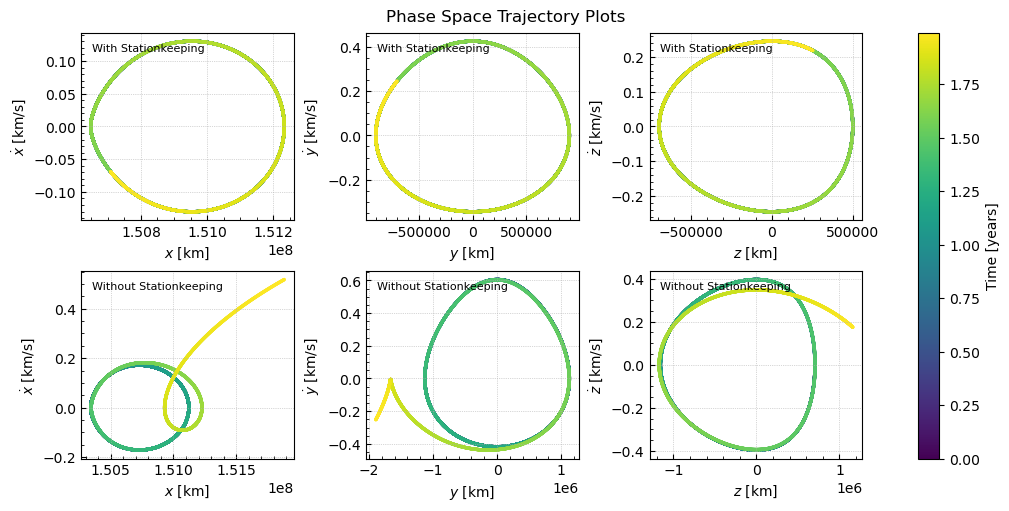

In [ ]:
# visualize
n = np.sqrt(6.6711e-11*(M_E+M_S)/((r12*1000)**3)) # mean motion from kepler's 3rd law
TU = 1/n # seconds
TU = TU / 86400 # days
TU # time unit

# phase space trajectories
fig, axs = plt.subplots(2,3,figsize=(10,5),constrained_layout=True)
for k in range(6):
    r, c = k // 3, k % 3
    if r == 0:
        pos = traj[:,c]
        vel = traj[:,c+3]
        t = times
        textlabel = 'With Stationkeeping'
    else:
        pos = traj_nocontrol[:,c]
        vel = traj_nocontrol[:,c+3]
        t = times_nocontrol
        textlabel = 'Without Stationkeeping'
    if c == 0:
        xlabel, ylabel = r'$x$ [km]', r'$\dot{x}$ [km/s]'
    elif c == 1:
        xlabel, ylabel = r'$y$ [km]', r'$\dot{y}$ [km/s]'
    else:
        xlabel, ylabel = r'$z$ [km]', r'$\dot{z}$ [km/s]'

    im = axs[r,c].scatter(pos * r12, vel * r12 / TU / 84600, c=t * TU / 365,s=2.0)
    axs[r,c].set_xlabel(xlabel)
    axs[r,c].set_ylabel(ylabel)
    axs[r,c].grid(visible=True,axis='both',linestyle=':',linewidth=0.5)
    axs[r,c].minorticks_on()
    axs[r,c].tick_params(axis='both',which='both',direction='in',labelsize=10)
    axs[r,c].text(0.05,0.9,textlabel, transform=axs[r,c].transAxes,fontsize=8)

fig.colorbar(im,ax=axs,label='Time [years]')
fig.suptitle('Phase Space Trajectory Plots')
plt.show()

### Stationkeeping Over Time

In [ ]:
indices = np.arange(0, 50, 6)
decade = 365.25 * 10 / TU
z0s = []
tot_dv = []
for j, ind in enumerate(indices):
    s0 = X0_range[ind]

    traj, dvs, dv_times, times = stationkeep(mu, s0, X_nom=s0, Tfull=decade/2, dt=0.001, no_control=False)

    z0s.append(s0[2])
    tot_dv.append(np.sum(dvs))

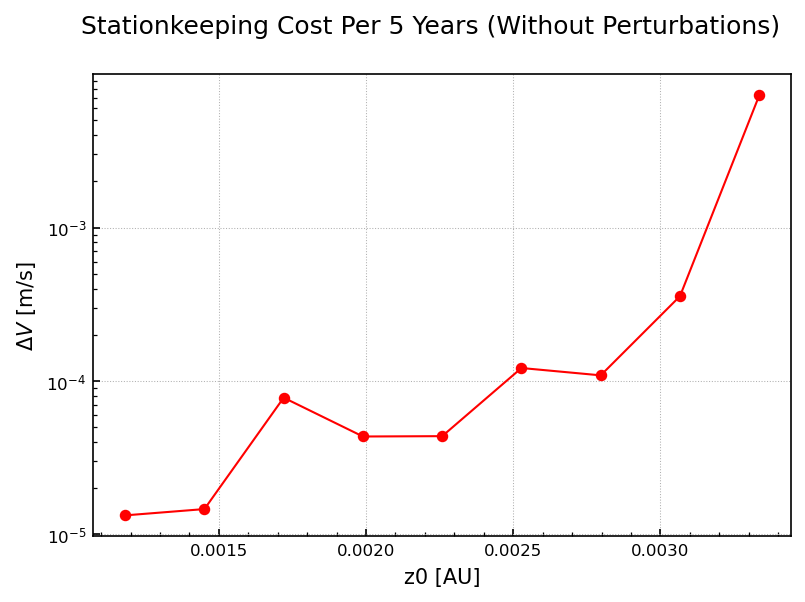

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(6,4),dpi=150)
ax.plot(np.array(z0s),np.array(np.abs(tot_dv)) * r12 * 1000 / TU / 86400,color='r',markersize=4.5,linestyle='-',linewidth=1.0,marker='o')
ax.set_yscale('log')
ax.grid(visible=True,axis='both',linestyle=':',linewidth=0.5)
ax.set_xlabel('z0 [AU]')
ax.set_ylabel(r'$\Delta V$ [m/s]')
ax.minorticks_on()
ax.tick_params(axis='both',which='both',direction='in',labelsize=8)
fig.suptitle('Stationkeeping Cost Per 5 Years (Without Perturbations)')
plt.show()